<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/01_bitwise_operations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bitwise operations

Bitwise operations work on every pixel independently. For binary images (pixels are either 0 or
255) they behave like set operations on the white regions:

| Operation | Result is white where |
|---|---|
| AND | both images are white |
| OR | at least one image is white |
| XOR | exactly one image is white |
| NOT | the image is black |

They are mostly used for masking, for example to keep only part of a photo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

## Two test images

Instead of loading images from disk we draw two shapes that overlap, so the result of each
operation is easy to check by eye.

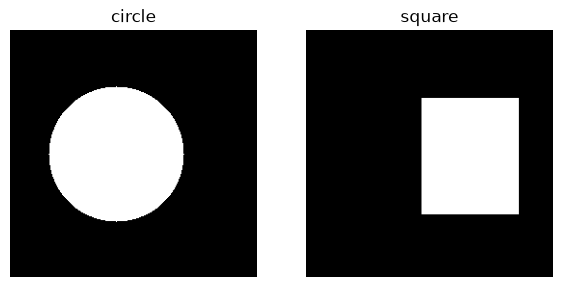

In [2]:
size = 256
circle = np.zeros((size, size), dtype=np.uint8)
square = np.zeros((size, size), dtype=np.uint8)

cv2.circle(circle, (110, 128), 70, 255, -1)              # white filled circle
cv2.rectangle(square, (120, 70), (220, 190), 255, -1)    # white filled square

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(circle); ax[0].set_title("circle")
ax[1].imshow(square); ax[1].set_title("square")
for a in ax:
    a.axis("off")
plt.show()

## Pixel by pixel

The loop below goes over every pixel and applies the operator to the two pixel values. Python's
`&`, `|` and `^` work on the bits of the numbers, so this also works for grey values, not just for
0 and 255.

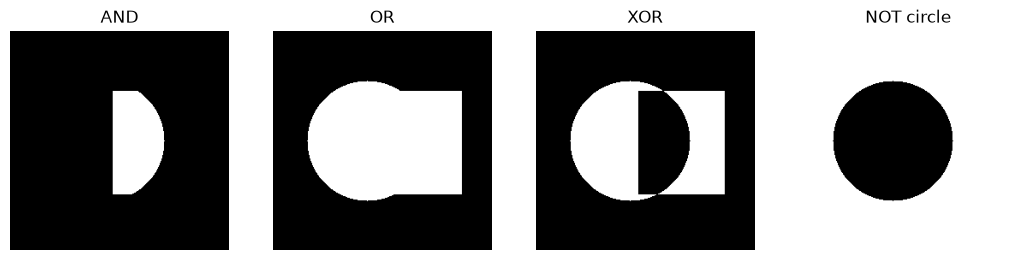

In [3]:
def bitwise(a, b, op):
    out = np.zeros_like(a)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            x, y = int(a[i, j]), int(b[i, j])
            if op == "and":
                out[i, j] = x & y
            elif op == "or":
                out[i, j] = x | y
            elif op == "xor":
                out[i, j] = x ^ y
    return out


def bitwise_not(a):
    return 255 - a   # flipping all 8 bits of a uint8 is the same as 255 - value


results = {
    "AND": bitwise(circle, square, "and"),
    "OR": bitwise(circle, square, "or"),
    "XOR": bitwise(circle, square, "xor"),
    "NOT circle": bitwise_not(circle),
}

fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for a, (name, img) in zip(ax, results.items()):
    a.imshow(img)
    a.set_title(name)
    a.axis("off")
plt.show()

## Comparison with OpenCV

OpenCV has the same operations built in. They should give exactly the same images.

In [4]:
opencv = {
    "AND": cv2.bitwise_and(circle, square),
    "OR": cv2.bitwise_or(circle, square),
    "XOR": cv2.bitwise_xor(circle, square),
    "NOT circle": cv2.bitwise_not(circle),
}
for name in results:
    print(f"{name:<11} same as OpenCV: {np.array_equal(results[name], opencv[name])}")

AND         same as OpenCV: True
OR          same as OpenCV: True
XOR         same as OpenCV: True
NOT circle  same as OpenCV: True


## Using a mask

The most common use of AND is masking. Where the mask is 255 (all bits set) the pixel is kept,
and where it is 0 the pixel becomes black.

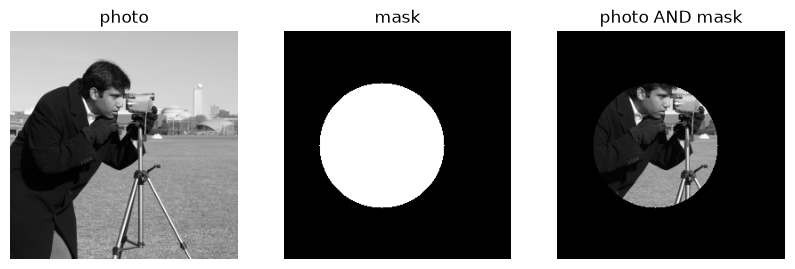

In [5]:
photo = cv2.resize(data.camera(), (size, size))
masked = cv2.bitwise_and(photo, circle)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, img, title in zip(ax, [photo, circle, masked], ["photo", "mask", "photo AND mask"]):
    a.imshow(img)
    a.set_title(title)
    a.axis("off")
plt.show()

The loop version is slow because Python handles one pixel at a time. NumPy can do the same thing
on the whole array at once with `np.bitwise_and(circle, square)` or simply `circle & square`.